# Can many trees beat one line? Random forests and gradient boosting for Waze churn

**Governing question.** A single decision tree ranked Waze users by churn risk worse than a linear (softmax) score: cross-validated average precision (AP) ≈ 0.36 against ≈ 0.39 (notebook 03). Its weakness was high variance and coarse scores. Ensembles address exactly that. A **random forest** averages hundreds of de-correlated trees, and **gradient boosting** adds small trees one at a time, each correcting the last. Can either reach or beat the linear baseline? And what do the best ensembles reveal about the *shape* of churn risk?

**Intended user.** The Waze product manager deciding whom to contact. A better ranking means more churners reached for the same outreach budget.

**Evidence rules.** As in notebook 03, everything here uses cross-validation on the 10,724 development users. The sealed test set stays closed until the cross-family model-selection milestone, so it is never used to choose among the many settings tried here.

**Road map.** §1 data → §2 evaluation design → §3 the mathematics of bagging and boosting → §4 verification of the student implementations → §5 random forests → §6 gradient boosting → §7 paired comparison with the baseline and trusted references → §8 what the boosted model learned → §9 failure analysis → §10 decision.

## 1. Data boundary

Unchanged from notebooks 02–03 (see `docs/DATASET_CARD.md`): 14,299 labeled synthetic Waze users, `churned` = 1 for 17.7%, the 11 package `FEATURE_COLUMNS`, and the same-month timing caveat. Tree ensembles split on raw values, so no scaling is needed.

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import average_precision_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from dsm_project.algorithms import create_student_algorithm
from dsm_project.config import load_config
from dsm_project.data.waze import WazeChurnAdapter
from dsm_project.experiments import split_supervised_task

config = load_config(Path("configs/waze.toml"))
dataset = WazeChurnAdapter().load(config)
split = split_supervised_task(dataset, config, task_name="classification")
dev_x, dev_y = split.train_features, split.train_targets
x_array, y_array = dev_x.to_numpy(), dev_y.to_numpy()
feature_names = list(dev_x.columns)
print(f"development users: {len(dev_x):,} | churn rate {dev_y.mean():.3f} | "
      f"sealed test users (not used): {len(split.test_features):,}")

development users: 10,724 | churn rate 0.177 | sealed test users (not used): 3,575


## 2. Evaluation design

- **Folds.** The same 5-fold stratified split (seed 438) as notebooks 02–03, so every model is judged on identical held-out users.
- **Metric.** Average precision on out-of-fold churn probabilities. The churn-rate baseline is 0.177, the student softmax baseline ≈ 0.39, and the best single tree ≈ 0.36.
- **Tuning.** Random forest: leaf size, plus all features versus a random subset per split. Gradient boosting: tree depth and the number of stages, read off one learning curve per depth instead of refitting for every stage count.
- **Final comparison.** The best forest and the best boosting model are compared with softmax regression on the same 15 folds (5 folds × 3 repeats), along with scikit-learn's implementations of the same settings as trusted references.
- **Selection rule (fixed in advance).** Highest mean CV AP; differences under 0.005 are ties, broken toward the simpler model (fewer interactions, fewer trees).

## 3. The mathematics

### 3.1 Random forest: averaging to reduce variance

Each tree $b = 1, \dots, B$ is grown on a **bootstrap sample**, $n$ users drawn with replacement, and at each split considers only a random subset of $m$ features (here $m = \lfloor\sqrt{11}\rfloor = 3$). The forest averages the trees' churn probabilities:

$$
\hat p(x) = \frac{1}{B}\sum_{b=1}^{B} \hat p_b(x).
$$

If each tree's prediction has variance $\sigma^2$ and any two trees are correlated with coefficient $\rho$, the average has variance

$$
\operatorname{Var}\big[\hat p(x)\big] = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2 .
$$

More trees shrink the second term; bootstrapping and feature sampling shrink $\rho$. The bias of a forest is roughly that of one of its trees, so a forest of deep, low-bias trees can rank much better than any single tree. About $(1 - 1/n)^n \approx 37\%$ of users are left out of each bootstrap sample. Scoring every user only with the trees that did not see them gives a free **out-of-bag** (OOB) estimate of held-out performance.

### 3.2 Gradient boosting: correcting residuals stage by stage

Boosting builds a log-odds score $F(x)$ additively. Start from the log-odds of the churn rate, $F_0 = \log\frac{\bar y}{1-\bar y}$. With $p_i = \sigma(F(x_i))$, the log-loss has negative gradient $r_i = y_i - p_i$, the residual. Each stage $m$:

1. fits a small regression tree to the residuals $r_i$;
2. sets each leaf's value to one Newton step on the log-loss, $\gamma = \dfrac{\sum_{i \in \text{leaf}} r_i}{\sum_{i\in\text{leaf}} p_i(1-p_i)}$;
3. updates $F \leftarrow F + \eta\,\gamma_{\text{leaf}(x)}$ with learning rate $\eta$.

**Depth controls interaction order.** A tree of depth $d$ can combine up to $d$ features in one leaf. With **depth 1** (stumps), each stage uses a single feature, so the final model is exactly *additive*:

$$
F(x) = F_0 + \sum_{j=1}^{11} f_j(x_j),
$$

where each $f_j$ is a step function learned from data. That is the same structure as logistic regression ($f_j(x_j) = w_j x_j$), except that each $f_j$ may bend. Comparing depths 1, 2, and 3 therefore tests directly whether interactions or non-linear shapes carry churn signal.

## 4. Student implementation and verification

| Component | Package location | Key evidence (`tests/test_ensembles.py`) |
| --- | --- | --- |
| `RegressionTree` (boosting base learner) | `student/trees.py` | hand-computed weighted split; same leaves and predictions as scikit-learn's `DecisionTreeRegressor` |
| `RandomForest` | `student/ensembles.py` | one un-randomized tree equals `ClassificationTree`; probabilities are the mean of the trees'; variance across seeds falls more than 4× from 1 to 25 trees; out-of-bag rows really were left out; accuracy within 0.03 of scikit-learn's forest |
| `GradientBoostingBinaryClassifier` | `student/ensembles.py` | hand-computed Newton leaf values; training scores and per-stage loss identical to scikit-learn's `GradientBoostingClassifier`; stump contributions add up to the full score |

A forest cannot match scikit-learn *exactly*, because the two use different random number generators to draw bootstrap samples. Boosting is deterministic, so it can. One subtlety came up in testing: in a node with only two users, every feature that separates them is an equally good split, and scikit-learn breaks such ties at random. The two implementations then fit the training users identically but may route a *new* user differently at that node. The live check below compares the boosted models on the development users themselves.

In [2]:
subset = slice(0, 3000)  # a quick check on 3,000 development users
student_gb = create_student_algorithm("gradient_boosting", n_estimators=60, max_depth=2).fit(
    x_array[subset], y_array[subset])
trusted_gb = GradientBoostingClassifier(n_estimators=60, max_depth=2, random_state=0).fit(
    x_array[subset].astype(np.float32), y_array[subset])
difference = np.abs(student_gb.decision_function(x_array[subset])
                    - trusted_gb.decision_function(x_array[subset].astype(np.float32))).max()
print(f"max |student − scikit-learn| boosted score on the training users: {difference:.1e}")

max |student − scikit-learn| boosted score on the training users: 4.0e-15


The difference is at the level of floating-point rounding: the student boosting implementation reproduces scikit-learn's algorithm on real Waze data.

## 5. Random forests

We vary the minimum leaf size: 1 grows each tree fully, the classic random forest; larger leaves make each tree smoother. Each forest has 100 trees. We also try one forest that considers all 11 features at every split (plain bagging) to see whether feature sampling helps. For each setting we report cross-validated AP and, from a single fit on all development users, the out-of-bag AP.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=438)


def out_of_fold(make_model):
    scores = np.zeros(len(y_array))
    for train, valid in cv.split(x_array, y_array):
        scores[valid] = make_model().fit(x_array[train], y_array[train]).predict_proba(
            x_array[valid])[:, 1]
    return scores


forest_rows = {}
for leaf, max_features in [(1, "sqrt"), (20, "sqrt"), (50, "sqrt"), (100, "sqrt"),
                           (200, "sqrt"), (100, None)]:
    start = time.time()

    def make(leaf=leaf, max_features=max_features):
        return create_student_algorithm("random_forest", n_estimators=100, min_samples_leaf=leaf,
                                        max_features=max_features, random_state=0)

    cv_scores = out_of_fold(make)
    oob = make().fit(x_array, y_array).oob_proba_[:, 1]
    forest_rows[(leaf, "all 11" if max_features is None else "√d = 3")] = {
        "CV AP": average_precision_score(y_array, cv_scores),
        "OOB AP": average_precision_score(y_array, oob),
        "seconds": time.time() - start,
    }
forest_table = pd.DataFrame(forest_rows).T
forest_table.index.names = ["min_samples_leaf", "features per split"]
display(forest_table.round(3))

,,CV AP,OOB AP,seconds
min_samples_leaf,features per split,,,
1,√d = 3,0.343,0.337,58.058
20,√d = 3,0.370,0.370,18.220
50,√d = 3,0.375,0.379,11.177
100,√d = 3,0.377,0.381,8.302
200,√d = 3,0.375,0.376,6.320
100,all 11,0.378,0.379,23.316


**Reading the table.**

- **Averaging rescues deep trees, but not fully.** A forest of fully grown trees (leaf size 1) reaches AP ≈ 0.34. That is far above a single unpruned tree (≈ 0.20 in notebook 03), but still a little below the best *pruned* single tree (≈ 0.36). Averaging removed most of the variance, not all of it.
- **Smoother trees help further.** Requiring 50–100 users per leaf lifts the forest to AP ≈ 0.375–0.38. With a weak, noisy signal, even averaged deep trees fit too much noise.
- **Feature sampling makes no measurable difference here** (0.377 with 3 features per split versus 0.378 with all 11), but it makes the forest about three times faster. With two dominant signals, active days and tenure, the trees end up highly correlated either way, so de-correlating them has little to gain.
- **Out-of-bag estimates track cross-validation closely** (within about 0.006 AP), so OOB is a cheap, trustworthy way to tune forests.

The best forest (100-user leaves, 3 features per split) reaches AP ≈ 0.38: better than any single tree, still short of softmax at ≈ 0.39.

## 6. Gradient boosting

For each tree depth we fit 600 stages once per fold and read the out-of-fold AP after 50, 100, …, 600 stages from the staged predictions. Smaller learning rates are used for deeper trees, the usual practice because each deeper stage is a bigger step.

,depth 1 (η = 0.1),depth 2 (η = 0.05),depth 3 (η = 0.03)
stages,,,
25,0.3598,0.3686,0.3765
50,0.3769,0.3806,0.3784
100,0.3884,0.3864,0.3801
150,0.3900,0.3829,0.3775
200,0.3902,0.3827,0.3767
300,0.3894,0.3810,0.3741
400,0.3881,0.3782,0.3709
600,0.3859,0.3715,0.3659


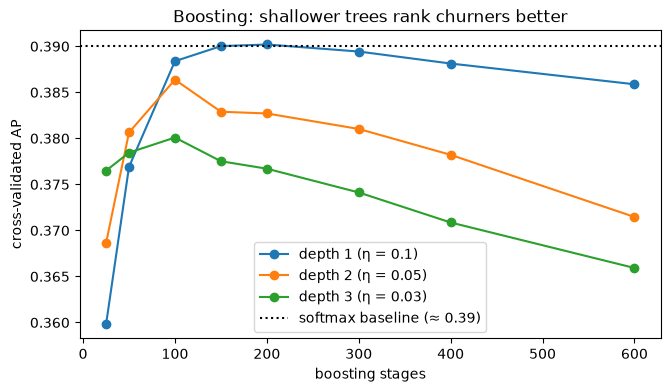

In [4]:
checkpoints = np.array([25, 50, 100, 150, 200, 300, 400, 600])
curves = {}
for depth, rate in [(1, 0.1), (2, 0.05), (3, 0.03)]:
    staged = {c: np.zeros(len(y_array)) for c in checkpoints}
    for train, valid in cv.split(x_array, y_array):
        model = create_student_algorithm("gradient_boosting", n_estimators=600,
                                         learning_rate=rate, max_depth=depth).fit(
            x_array[train], y_array[train])
        for stage, probability in enumerate(model.staged_predict_proba(x_array[valid]), start=1):
            if stage in staged:
                staged[stage][valid] = probability[:, 1]
    curves[f"depth {depth} (η = {rate})"] = [average_precision_score(y_array, staged[c])
                                            for c in checkpoints]
curves = pd.DataFrame(curves, index=pd.Index(checkpoints, name="stages"))

fig, ax = plt.subplots(figsize=(7.5, 4))
for column in curves:
    ax.plot(curves.index, curves[column], "o-", label=column)
ax.axhline(0.39, color="black", linestyle=":", label="softmax baseline (≈ 0.39)")
ax.set(xlabel="boosting stages", ylabel="cross-validated AP",
       title="Boosting: shallower trees rank churners better")
ax.legend()
display(curves.round(4))

**Reading the curves.**

- **Stumps (depth 1) are best.** They peak at AP ≈ 0.39 after about 200 stages, tying the softmax baseline. Depth 2 peaks lower and earlier (≈ 0.386 at 100 stages), and depth 3 lower still (≈ 0.38).
- **More interaction means more overfitting, not more signal.** Deeper boosting peaks sooner and then declines as it starts fitting noise.
- **Every curve eventually falls.** The number of stages is a real hyperparameter and has to be chosen on held-out data; the training loss alone would keep improving.

By the selection rule, the boosting candidate is **depth 1, η = 0.1, 200 stages**.

## 7. Paired comparison with the baseline and trusted references

The three best student models are compared on the same 15 folds, together with scikit-learn's forest and boosting with the same settings as trusted references.

In [5]:
repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=438)
candidates = {
    "student softmax": make_pipeline(
        StandardScaler(),
        create_student_algorithm("softmax_regression", l2_penalty=0.1, learning_rate=0.5)),
    "student boosted stumps": create_student_algorithm(
        "gradient_boosting", n_estimators=200, learning_rate=0.1, max_depth=1),
    "student random forest": create_student_algorithm(
        "random_forest", n_estimators=200, min_samples_leaf=100, random_state=0),
    "reference: sklearn boosted stumps": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=1, random_state=0),
    "reference: sklearn random forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=100, random_state=0, n_jobs=1),
}
fold_ap = {name: cross_val_score(model, dev_x, dev_y, cv=repeated, scoring="average_precision")
           for name, model in candidates.items()}
summary = pd.DataFrame({
    "mean AP": {k: v.mean() for k, v in fold_ap.items()},
    "sd across folds": {k: v.std() for k, v in fold_ap.items()},
    "mean gap to softmax": {k: (v - fold_ap["student softmax"]).mean() for k, v in fold_ap.items()},
    "sd of gap": {k: (v - fold_ap["student softmax"]).std() for k, v in fold_ap.items()},
    "folds better than softmax": {k: int((v > fold_ap["student softmax"]).sum())
                                  for k, v in fold_ap.items()},
})
display(summary.round(4))

,mean AP,sd across folds,mean gap to softmax,sd of gap,folds better than softmax
student softmax,0.3915,0.0203,0.0000,0.0000,0
student boosted stumps,0.3926,0.0191,0.0011,0.0041,10
student random forest,0.3854,0.0181,-0.0061,0.0080,4
reference: sklearn boosted stumps,0.3926,0.0191,0.0011,0.0041,10
reference: sklearn random forest,0.3859,0.0180,-0.0056,0.0067,4


**Reading the comparison.**

- **Boosted stumps tie softmax regression.** Stumps score higher on 10 of the 15 folds, but by only 0.001 AP on average, a quarter of the fold-to-fold spread of the gap (0.004). Neither model is better in any meaningful sense.
- **The random forest is a little behind** softmax: 0.006 AP lower on average and better on only 4 of 15 folds.
- **The trusted references agree.** scikit-learn's boosting with identical settings matches the student version's mean and spread to four decimals, and its forest is within 0.001 AP of the student forest (different random bootstrap samples). The conclusions do not depend on the student implementations.

## 8. What the boosted model learned

Because boosted stumps are additive, the model is a sum of one-feature curves. We can extract each curve exactly (`stump_contribution`) and compare it with what softmax regression assumes: a straight line in log-odds. The cell below fits both models on all development users and plots the learned curves for the four most influential features.

log-odds range of each feature's stump curve (1st–99th percentile):
{'activity_days': 2.0, 'n_days_after_onboarding': 1.18, 'driving_days': 0.78, 'drives': 0.52, 'total_navigations_fav1': 0.46, 'duration_minutes_drives': 0.22, 'total_navigations_fav2': 0.11, 'total_sessions': 0.08, 'driven_km_drives': 0.07, 'sessions': 0.04, 'is_iphone': 0.0}


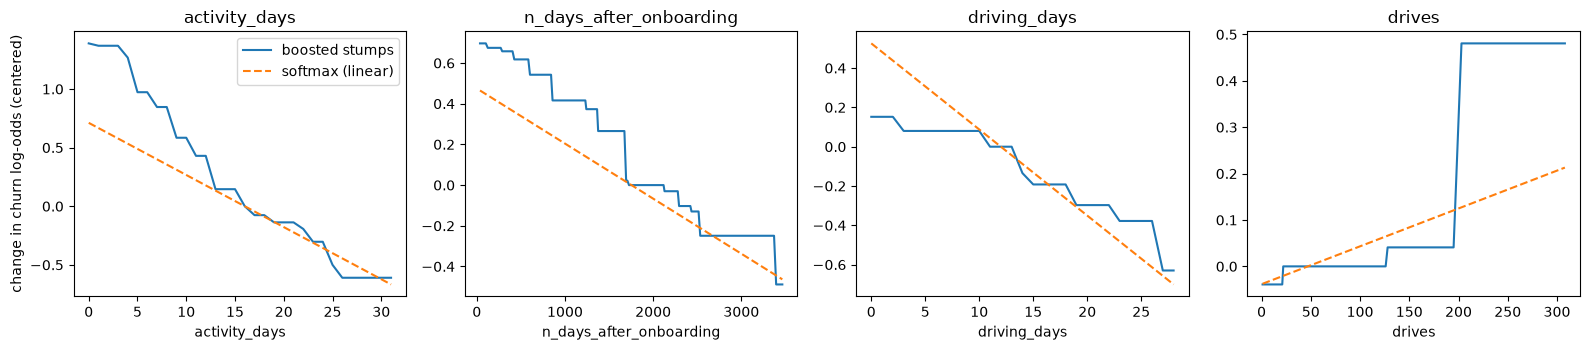

In [6]:
stumps = create_student_algorithm("gradient_boosting", n_estimators=200, learning_rate=0.1,
                                  max_depth=1).fit(x_array, y_array)
linear = make_pipeline(StandardScaler(), create_student_algorithm(
    "softmax_regression", l2_penalty=0.1, learning_rate=0.5)).fit(dev_x, dev_y)
scaler, softmax_model = linear[0], linear[-1]
weights = (softmax_model.coef_[:, 1] - softmax_model.coef_[:, 0]) / scaler.scale_

spread = {}
for j, name in enumerate(feature_names):
    grid = np.quantile(x_array[:, j], np.linspace(0.01, 0.99, 200))
    spread[name] = np.ptp(stumps.stump_contribution(j, grid))
top = sorted(spread, key=spread.get, reverse=True)[:4]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, name in zip(axes, top, strict=True):
    j = feature_names.index(name)
    grid = np.quantile(x_array[:, j], np.linspace(0.01, 0.99, 200))
    curve = stumps.stump_contribution(j, grid)
    line = weights[j] * (grid - np.median(x_array[:, j]))
    ax.plot(grid, curve - np.median(curve), label="boosted stumps")
    ax.plot(grid, line, "--", label="softmax (linear)")
    ax.set(xlabel=name, title=name)
axes[0].set_ylabel("change in churn log-odds (centered)")
axes[0].legend()
plt.tight_layout()
print("log-odds range of each feature's stump curve (1st–99th percentile):")
print(pd.Series(spread).sort_values(ascending=False).round(2).to_dict())

**Reading the curves.** The boosted model agrees with the linear model on *direction* but shows where the straight line is too simple:

- **Active days** has the largest effect (a 2.0 log-odds range) and is clearly *curved*. Risk drops steeply over the first ~10 days of activity and levels off above ~25 days. The linear model uses one average slope, understating the difference between 0 and 10 days.
- **Tenure** (1.2 log-odds range) declines in steps that follow the straight line closely.
- **Driving days** is flat at the low end and then declines. It is strongly correlated with active days, which takes the credit for the low-end drop.
- **Drives** shows a jump at about 200 drives a month: those users carry about 0.5 extra log-odds of churn risk. They are 5.1% of development users and churn at 26% versus 17% for everyone else, the same "very heavy driver" pattern seen in notebook 03's rules and in my earlier analysis.

Why, then, does this flexibility not raise AP? The scores from the boosted stumps and from softmax are correlated at 0.97 (§9). The bends change the order of relatively few users, mostly within the high-risk group that both models already flag. The churn signal is **additive**, with no useful interactions, and **mostly monotone**. A straight-line model captures nearly all of its ranking value. The bends are still worth turning into explicit features (for example a heavy-driver flag or a log transform of active days) that a transparent linear model can use.

## 9. Failure analysis

**Active churners.** At a fixed outreach budget (the riskiest 20% of development users, out-of-fold), which churners does each model reach?

In [7]:
softmax_oof = out_of_fold(lambda: make_pipeline(StandardScaler(), create_student_algorithm(
    "softmax_regression", l2_penalty=0.1, learning_rate=0.5)))
stumps_oof = out_of_fold(lambda: create_student_algorithm(
    "gradient_boosting", n_estimators=200, learning_rate=0.1, max_depth=1))
forest_oof = out_of_fold(lambda: create_student_algorithm(
    "random_forest", n_estimators=200, min_samples_leaf=100, random_state=0))

churners = y_array == 1
group = pd.cut(dev_x["activity_days"], [-1, 10, 20, 31],
               labels=["0–10 days", "11–20 days", "21–31 days"]).to_numpy()
reach = {}
for name, scores in (("softmax", softmax_oof), ("boosted stumps", stumps_oof),
                     ("random forest", forest_oof)):
    flagged = scores >= np.quantile(scores, 0.8)
    row = pd.Series(flagged[churners]).groupby(group[churners]).mean()
    row["all churners"] = flagged[churners].mean()
    reach[name] = row
display(pd.DataFrame(reach).round(3))

agreement = np.corrcoef([softmax_oof, stumps_oof, forest_oof])
print("correlation of out-of-fold scores (softmax, stumps, forest):")
print(np.round(agreement, 3))

,softmax,boosted stumps,random forest
0–10 days,0.691,0.685,0.699
11–20 days,0.090,0.075,0.031
21–31 days,0.000,0.004,0.000
all churners,0.452,0.445,0.443


correlation of out-of-fold scores (softmax, stumps, forest):
[[1.    0.972 0.971]
 [0.972 1.    0.966]
 [0.971 0.966 1.   ]]


The blind spot is unchanged: essentially no churner active on more than 20 days is reached (at most 0.4%), and all three models reach about the same share of churners overall (44–45%). Their out-of-fold scores are correlated at about 0.97. They rank users in nearly the same order, which is why swapping or combining them changes little.

**Failure sources.**

- *Data / task formulation (dominant):* one month of usage counts cannot separate active users who are about to leave from those who will stay. Every model family hits the same ceiling, AP ≈ 0.39.
- *Overfitting:* deeper trees, unpruned forests, and too many boosting stages all hurt held-out ranking. Their settings must be tuned on held-out data, as done here.
- *Cost:* the forest and boosting models take seconds to tens of seconds to fit, against well under a second for softmax regression, for no gain in ranking.
- *Implementation:* none found. Boosting matches scikit-learn exactly on training users, and the forest matches scikit-learn's performance.

## 10. Conclusion and decision

**Answer.** Ensembles fix the single tree's weaknesses: the best random forest (AP ≈ 0.38) and the best gradient boosting (AP ≈ 0.39) both beat it clearly. But neither beats the linear baseline. Boosted stumps *tie* softmax regression, and the forest trails it slightly. The best boosting model is the most restricted one (additive stumps, no interactions). Its learned curves show real but modest bends (steeper risk at very low activity, a jump for very heavy drivers) that change the ranking of too few users to improve AP.

**Decision.**

- Keep **student softmax regression** as the leading promotion candidate: same ranking quality, fastest, and directly interpretable.
- Carry **boosted stumps** (depth 1, η = 0.1, 200 stages) into final model selection as the strongest non-linear alternative.
- Do not promote the random forest.

The test set remains sealed. These candidates will be compared on it once, in the model-selection notebook.

**Next steps.**

1. **Engineered features**, drawing on my earlier analysis and on §8: a heavy-driver flag, a curved transform of active days, the share of lifetime sessions that happened this month, and km per driving day. Features that capture *changes* in behavior are the only plausible route to the active churners.
2. **Unsupervised segmentation** (k-means and PCA): describe user groups for the PM, independently of the churn label.
3. **Model selection (lecture 16):** freeze the candidates, open the test set once, and promote the winner into the API.